## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

```python
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()
```

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI 

Complete all questions in the following cells without generative AI. 
Then commit and push the notebook before beginning Phase 2. 

**Declaration:** I completed this version without generative AI. 

**Student(s):** Jacob Khaykin

**Date:** 10/21/2026

[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]
Unique tokens, singletons, median: 48691 29404 1.0


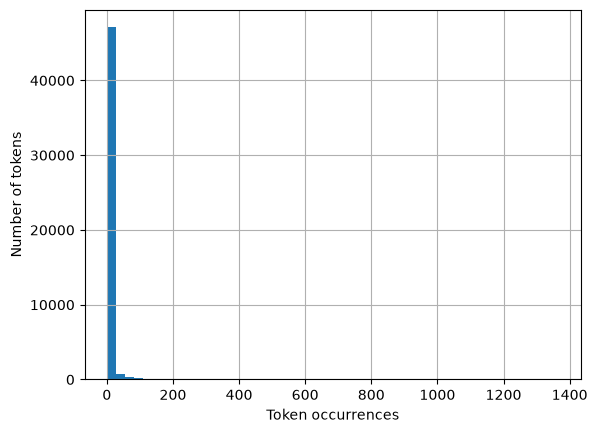

Train/test rows: 14907 3727


Original train/test R2: 0.7677733084118992 0.6571173475409768
aging                0.996514
helvetica,           0.892177
localized            0.787934
background-image:   -0.780070
thermal              0.671019
12px;                0.629280
rcs                  0.553536
exercise!            0.542180
burning             -0.515023
#000000;             0.502902
dtype: float64


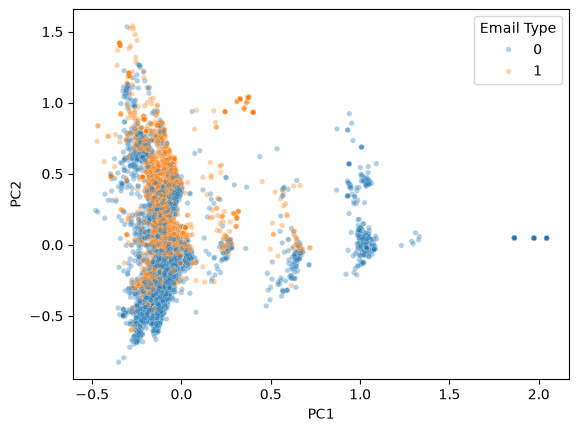

PC1/PC2 variance shares: [0.01113085 0.00861197]


PCA train/test R2: 0.766896761127783 0.6613559301353326
Variance retained: 0.9998504785919669


In [1]:
import pickle
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

with open('data/all_tokens.pickle', 'rb') as file: token_count = Counter(pickle.load(file))
counts = pd.Series(token_count.values())
print(token_count.most_common(10))
print('Unique tokens, singletons, median:', len(counts), (counts == 1).sum(), counts.median())
counts.hist(bins=50)
plt.xlabel('Token occurrences')
plt.ylabel('Number of tokens')
plt.show()

df = pd.read_parquet('data/Phishing_clean.parquet')
X, y = df.drop(columns='Email Type'), df['Email Type']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=65)
print('Train/test rows:', len(X_train), len(X_test))
linear_fit = LinearRegression().fit(X_train, y_train)
print('Original train/test R2:', linear_fit.score(X_train, y_train), linear_fit.score(X_test, y_test))
coef = pd.Series(linear_fit.coef_, index=X.columns)
print(coef.loc[coef.abs().sort_values(ascending=False).head(10).index])

pca_two = PCA(n_components=2).fit(X)
pcs = pca_two.transform(X)
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=y, alpha=0.35, s=15)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()
print('PC1/PC2 variance shares:', pca_two.explained_variance_ratio_)

pca = PCA(n_components=2610).fit(X_train)
train_pcs, test_pcs = pca.transform(X_train), pca.transform(X_test)
pca_fit = LinearRegression().fit(train_pcs, y_train)
print('PCA train/test R2:', pca_fit.score(train_pcs, y_train), pca_fit.score(test_pcs, y_test))
print('Variance retained:', pca.explained_variance_ratio_.sum())


Q1

The histogram appears skewed to the right. Because most tokens appear only a few times, and a small number appear much more often, this creates the long right tail. Specifically, out of 48,691 different tokens, 29,404 appear only once. The actual most common token is new, appearing 1,365 times.

Q2

The 80/20 split gives 14,907 training emails and 3,727 test emails. The regression has a training R^2 of 0.7678 and a test R^2 of 0.6571. Because the training score is higher, this suggests some possible overfitting.

The largest coefficients in absolute value are aging (0.9965), helvetica, (0.8922), localized (0.7879), background-image: (-0.7801), and thermal (0.6710). The Positive coefficients push the prediction toward the phishing catagory, whereas the negative coefficients push it toward safe.

Q3

The safe and phishing emails overlap a lot. As Phishing emails tend to be higher on PC2 in the main group, with some smaller groups on the right are mostly safe. Together, they explain only about 1.97% of the variation.

Q4

Using the first 2,610 principal components gives a training R^2 of 0.7669 and a test R^2 of 0.6614. Compared with the prior results, the training score is slightly lower and the test score is slightly higher. Clearly, although PCA helped a little on this test set, the difference is small.

Q5

PCA combines related token features into fewer variables while keeping most of the variation. Consequently, this reduces overlapping information and can help limit overfitting. The problem is that the components are harder to interpret than individual words. Dropping components can also remove information useful for prediction. Therefore, there are definetly multiple tradeoffs.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

Phase 1 commit SHA ID: 3dc72f6a4cf99b0c495ee745533f4f79e9c11b57

### *Prompts used

I used ChatGPT Codex 6.1 Sol

My prompt: Hey chatgpt, you have access to my file attached to this chat, I have already completed phase 1, if you check what phase 2 is, you should let me know of any changes you would like to propose, make sure the changes are actually important and viable.

### *AI-proposed changes


1. Round the regression scores and coefficients to four decimal places and label the training and test scores clearly.
2. Label the scatterplot legend so that 0 means safe and 1 means phishing, while keeping the numeric labels and avoiding .map().
3. Revise the short written answers to explain the limited separation in the two-component plot, the small test-score improvement, and the interpretation limits of coefficients and PCA.

### *Evaluation of AI suggestions


1. Accept. This suggestion is okay, nothing too much.Rounding makes the output easier to read without changing either regression. The revised results were checked against the Phase 1 scores.

2. Accept. I used plt.legend() to label the scatterplot beter via the legend.

3. Accept. The answers keep the actual results and explain that the two plotted components capture only 1.97% of the variation. Furthermore, I changed it to avoid treating regression scores as classification accuracy or claiming that PCA always improves prediction. 

### AI-assisted solution in full

[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]
Unique tokens, singletons, median: 48691 29404 1.0


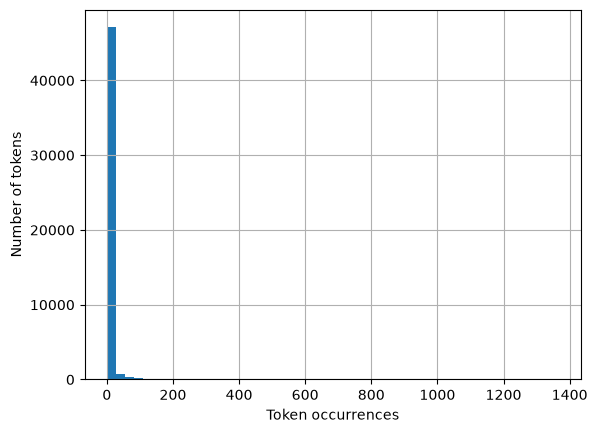

Train/test rows: 14907 3727


Original R2 (train, test): 0.7678 0.6571
aging                0.9965
helvetica,           0.8922
localized            0.7879
background-image:   -0.7801
thermal              0.6710
12px;                0.6293
rcs                  0.5535
exercise!            0.5422
burning             -0.5150
#000000;             0.5029
dtype: float64


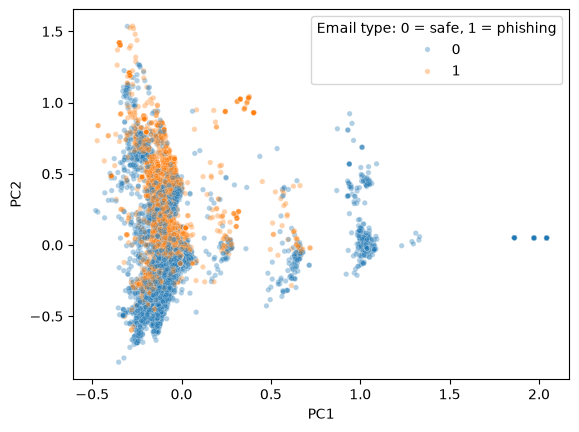

PC1/PC2 variance shares: [0.0111 0.0086]


PCA R2 (train, test): 0.7669 0.6614
Variance retained: 0.99985


In [1]:
import pickle
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

with open('data/all_tokens.pickle', 'rb') as file: token_count = Counter(pickle.load(file))
counts = pd.Series(token_count.values())
print(token_count.most_common(10))
print('Unique tokens, singletons, median:', len(counts), (counts == 1).sum(), counts.median())
counts.hist(bins=50)
plt.xlabel('Token occurrences')
plt.ylabel('Number of tokens')
plt.show()

df = pd.read_parquet('data/Phishing_clean.parquet')
X, y = df.drop(columns='Email Type'), df['Email Type']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=65)
print('Train/test rows:', len(X_train), len(X_test))
linear_fit = LinearRegression().fit(X_train, y_train)
print('Original R2 (train, test):', round(linear_fit.score(X_train, y_train), 4), round(linear_fit.score(X_test, y_test), 4))
coef = pd.Series(linear_fit.coef_, index=X.columns)
print(coef.loc[coef.abs().sort_values(ascending=False).head(10).index].round(4))

pca_two = PCA(n_components=2).fit(X)
pcs = pca_two.transform(X)
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=y, alpha=0.35, s=15)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title='Email type: 0 = safe, 1 = phishing')
plt.show()
print('PC1/PC2 variance shares:', pca_two.explained_variance_ratio_.round(4))

pca = PCA(n_components=2610).fit(X_train)
train_pcs, test_pcs = pca.transform(X_train), pca.transform(X_test)
pca_fit = LinearRegression().fit(train_pcs, y_train)
print('PCA R2 (train, test):', round(pca_fit.score(train_pcs, y_train), 4), round(pca_fit.score(test_pcs, y_test), 4))
print('Variance retained:', round(pca.explained_variance_ratio_.sum(), 6))


Q1

The histogram appears skewed to the right. Because most tokens appear only a few times, and a small number appear much more often, this creates the long right tail. Specifically, out of 48,691 different tokens, 29,404 appear only once. The actual most common token is new, appearing 1,365 times.

Q2

The 80/20 split gives 14,907 training emails and 3,727 test emails. The regression has a training R^2 of 0.7678 and a test R^2 of 0.6571. Because the training score is higher, this suggests some possible overfitting.

The largest coefficients in absolute value are aging (0.9965), helvetica, (0.8922), localized (0.7879), background-image: (-0.7801), and thermal (0.6710). The Positive coefficients push the prediction toward the phishing catagory, whereas the negative coefficients push it toward safe.

Q3

The safe and phishing emails overlap a lot. As Phishing emails tend to be higher on PC2 in the main group, with some smaller groups on the right are mostly safe. Together, they explain only about 1.97% of the variation.

Q4

Using the first 2,610 principal components gives a training R^2 of 0.7669 and a test R^2 of 0.6614. Compared with the prior results, the training score is slightly lower and the test score is slightly higher. Clearly, although PCA helped a little on this test set, the difference is small.

Q5

PCA combines related token features into fewer variables while keeping most of the variation. Consequently, this reduces overlapping information and can help limit overfitting. The components have zero covariance with each other in the training data and are ordered by how much variation they explain. Here, keeping 2,610 components instead of the original 2,711 token features retains about 99.9850% of the training variation while slightly improving the test R^2 from 0.6571 to 0.6614. The problem is that the components are harder to interpret than individual words. Dropping components can also remove information useful for prediction. Therefore, there are definitely multiple tradeoffs.


### Reflection on AI assistance



The main takeaway that I learned by doing this assignment is the fact PCA can reduce the number of features without losing much variation, but at the same time, a better test score is not guaranteed. For example, in this assignment, using 2,610 components changed the test R-squared from 0.6571 to 0.6614. That is a small improvement, so it would probably be too strong to say PCA made the model much better.

The AI revisions mostly just made the output and explanations clearer instead of changing something or actually finding a big error. For example, the scores were rounded and the plot legend explains the email labels. One limitation of the AI assistance was that it did not check whether the small improvement in test R-squared would hold with a different train-test split.

The revised code was run, and the regression results were compared with Phase 1. The regression PCA still uses only the training data. A Remaining concern would be the overlap in the two-component plot and whether or not the small score improvement would hold with a different split (instead of 80/20). 